# 01 — Understanding Bataan's synthetic outage events

**Guided lesson • Phase A • Source assessment: 12 October 2026**

This notebook explores **simulated events**, not verified PENELCO outages. The generator deliberately uses weather, vegetation and terrain to shape events. Its causes, durations, severity and probabilities are assumptions of that simulation. Describing those patterns does not validate real-world forecasting or identify real causes.

**Verified snapshot:** 10,608 events, 237 barangays, 12 municipalities; 2019–June 2026. Every reported result below is recomputed from the preserved files. Budget about 45–60 minutes for the lesson and exercises.

## 1. Learning objectives

After this lesson you should be able to:

1. Explain the observation unit: one row is one synthetic event assigned to its original barangay.
2. Preserve geographic codes as text and validate identifiers against boundary properties.
3. Check missingness, uniqueness, timestamps, duration consistency and overlapping events.
4. Distinguish event dates from the generator's declared coverage, using Asia/Manila (UTC+8).
5. Compare counts fairly when years and municipalities have different exposure.
6. Separate descriptive simulation results from outage risk, causal evidence and predictive skill.

No source files are written by the lesson. Transformations remain in memory. No model, large panel or application code is created.

## 2. Dataset introduction and provenance

Paths below are relative to the **current repository**, not the older paths embedded in the manifest.

| File | Role and grain | Important fields / units |
|---|---|---|
| `data/outages/synthetic_outage_events.csv` | Canonical event log; 10,608 × 51 | `outage_id`; text PSGC codes; names; offset-aware `start_time`, `end_time`; `duration_minutes`; generated cause/severity |
| `data/outages/run_manifest.json` | One generation run | Synthetic flag, seed 42, version 1.0.0, exposure interval, SHA-256, heuristic weights, retrospective NDVI policy |
| `data/boundaries/bataan_barangays.geojson` | 237 barangay polygons | Barangay/municipality PSGC and names; CRS84 longitude/latitude |
| `data/data_manifest.csv` | Catalog of copied sources | Current-byte checksums, old source paths, provenance and previous application usage |

The generator source was inspected read-only at `D:/PyCharmProjects/Outage Prediction/scripts/generate_synthetic_outages.py`. It uses heuristic weights, suppresses overlapping events within a barangay, rejects events extending beyond coverage, and clips simulated durations to 15–2,880 minutes. **We never run it.** The old catalog documents source lineage; it is not proof that every source remains suitable for this simplified app.

The CSV also contains event-time weather (rain in mm, wind in m/s, temperature in °C, pressure in hPa, soil moisture in m³/m³, CAPE in J/kg), annual NDVI (dimensionless), elevation (m) and slope (degrees). Generator scores/probabilities, post-event outcomes and annual retrospective NDVI must not become predictors just because they are present.

### Setup in PyCharm / uv

Select this project's `.venv/Scripts/python.exe` as the notebook interpreter and **Restart kernel → Run all**. Dependencies are recorded in `pyproject.toml` and pinned by `uv.lock`; from the repository root run `uv sync` if needed. The lesson itself uses pandas, NumPy, Matplotlib, IPython and Python's standard library. There are no package-install cells or network requests.

The root finder supports starting from the repository root or a folder below it. If PyCharm starts elsewhere, set its notebook working directory to this repository.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, GOLD = "#28618C", "#B67820"
pd.set_option("display.max_rows", 18)
pd.set_option("display.max_columns", 8)

In [2]:
root_candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next((path for path in root_candidates
                     if (path / "data/outages/synthetic_outage_events.csv").is_file()), None)
assert project_root is not None, "Set the working directory to this repository."
data_directory = project_root / "data"
source_paths = {
    "events": data_directory / "outages/synthetic_outage_events.csv",
    "run": data_directory / "outages/run_manifest.json",
    "boundaries": data_directory / "boundaries/bataan_barangays.geojson",
    "catalog": data_directory / "data_manifest.csv",
}
assert all(path.is_file() for path in source_paths.values())
print("Repository:", project_root)
print("Python:", platform.python_version())
display(pd.Series({name: importlib.metadata.version(name)
                   for name in ["pandas", "numpy", "matplotlib", "nbformat", "nbclient"]}, name="version"))

Repository: D:\PyCharmProjects\Outage Analytics and Prediction
Python: 3.14.6


pandas         3.0.6
numpy          2.5.4
matplotlib    3.11.2
nbformat      5.11.1
nbclient      0.11.0
Name: version, dtype: str

### A checksum ties our lesson to the selected run

`json.load` reads manifest metadata. SHA-256 fingerprints a file's bytes; matching fingerprints verify file identity, not scientific validity. We save fingerprints in memory now and compare them again at the end. The copied catalog still says `data/curated/...`; remove that historical prefix when resolving its entries in this repository. Files absent from that catalog, such as the added weather exports, need separate lineage checks in a later lesson.

In [3]:
def file_sha256(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

source_hashes_before = {name: file_sha256(path) for name, path in source_paths.items()}
with source_paths["run"].open(encoding="utf-8") as stream:
    run_manifest = json.load(stream)
assert run_manifest["is_synthetic"] is True
assert source_hashes_before["events"] == run_manifest["event_csv_sha256"]
catalog = pd.read_csv(source_paths["catalog"], dtype="string")
print("Catalog fields:", ", ".join(catalog.columns))
print("Run:", run_manifest["generator_version"], "— seed", run_manifest["seed"])
display(pd.Series(run_manifest["period"], name="declared coverage"))

Catalog fields: file_path, sha256, size_bytes, source_path, equivalent_source_paths, category, purpose, provenance, used_by_dashboard, used_by_analysis, used_by_ml, references, historical_sha256, historical_hash_status
Run: 1.0.0 — seed 42


requested_start                                                 2019-01-01 00:00
requested_end                                                   2026-06-30 23:00
start_local                                            2019-01-01 08:00:00+08:00
end_local                                              2026-06-30 23:00:00+08:00
candidate_hours                                                            65704
exposure_hours_per_barangay                                              65703.0
boundary_rule                  Both start and end must be within the inclusiv...
Name: declared coverage, dtype: object

### Load identifiers as text

PSGC codes begin with zeros. A numeric import can discard them, breaking geographic joins. `dtype` preserves their exact strings. `head` gives a small preview; `shape` gives row and column counts. We retain `events_raw` for checks and create a separate in-memory analysis copy later.

In [4]:
events_raw = pd.read_csv(source_paths["events"], dtype={
    "outage_id": "string", "barangay_psgc": "string", "municipality_psgc": "string"})
print(f"Rows: {len(events_raw):,}; columns: {events_raw.shape[1]}")
preview_columns = ["outage_id", "barangay_psgc", "municipality",
                   "start_time", "duration_minutes", "cause_category"]
display(events_raw[preview_columns].head(5))

Rows: 10,608; columns: 51


,outage_id,barangay_psgc,municipality,start_time,duration_minutes,cause_category
0,SYN-42-0300811022-20190101T0800,0300811022,Pilar,2019-01-01 08:00:00+08:00,98.59,Weather / Storm
1,SYN-42-0300808003-20190101T1300,0300808003,Morong,2019-01-01 13:00:00+08:00,110.67,Vegetation / Tree Contact
2,SYN-42-0300803016-20190101T1700,0300803016,City of Balanga,2019-01-01 17:00:00+08:00,94.26,Equipment / Technical
3,SYN-42-0300811019-20190101T2200,0300811019,Pilar,2019-01-01 22:00:00+08:00,336.17,Equipment / Technical
4,SYN-42-0300804021-20190102T0100,0300804021,Dinalupihan,2019-01-02 01:00:00+08:00,426.74,Vegetation / Tree Contact


## 3. Concept explanation: quality before charts

A **schema** defines expected fields and types. A dataset can satisfy its schema and still have weak provenance or unrealistic values. Missingness and duplicates are separate checks: an empty string can be a missing label, and two unique IDs can still refer to the same barangay/time.

An `assert` is a guard: it stops the lesson when an assumption fails. Never delete rows simply to make a guard pass. Inspect the failed records and discuss the source problem first.

### Required schema and full-column overview

The core schema below is deliberately explicit. Optional environmental and simulator fields are listed afterward, but none is silently selected for modeling.

In [5]:
required_columns = ["outage_id", "is_synthetic", "generator_version", "random_seed",
    "barangay_psgc", "barangay", "municipality_psgc", "municipality",
    "start_time", "end_time", "duration_minutes", "year", "month", "hour",
    "day_of_week", "cause_category", "severity_class"]
assert events_raw.columns.is_unique
assert set(required_columns).issubset(events_raw.columns), "Missing a required field."
assert events_raw["is_synthetic"].eq(True).all()
assert events_raw["generator_version"].eq(run_manifest["generator_version"]).all()
assert events_raw["random_seed"].eq(run_manifest["seed"]).all()
column_overview = pd.DataFrame({"dtype": events_raw.dtypes.astype(str),
                               "missing_count": events_raw.isna().sum()})
display(column_overview.loc[required_columns])
print("Other fields:", ", ".join(column_overview.drop(required_columns).index))

,dtype,missing_count
outage_id,string,0
is_synthetic,bool,0
generator_version,str,0
random_seed,int64,0
barangay_psgc,string,0
barangay,str,0
municipality_psgc,string,0
municipality,str,0
start_time,str,0
end_time,str,0


Other fields: synthetic_event_propensity, synthetic_event_generation_probability, cape_j_kg, ndvi_annual_mean, ndvi_year, ndvi_period_type, ndvi_context, ndvi_source_start, ndvi_source_end_exclusive, weather_spatial_resolution, era5_latitude, era5_longitude, era5_grid_resolution_degrees, weather_hazard_score, vegetation_exposure_score, terrain_exposure_score, wind_vegetation_interaction, rain_terrain_interaction, rainfall_score, wind_score, convective_score, soil_wetness_score, precipitation_mm, wind_speed_10m_m_s, wind_gusts_10m_m_s, soil_moisture_0_to_7cm_m3_m3, soil_moisture_7_to_28cm_m3_m3, temperature_2m_c, relative_humidity_2m_pct, surface_pressure_hpa, mean_elevation_m, mean_slope_deg, p90_slope_deg, elevation_relief_p95_p05_m


In [6]:
text_columns = events_raw.select_dtypes(include=["string", "object", "str"]).columns
blank_counts = events_raw[text_columns].apply(lambda column: column.str.strip().eq("").sum())
missing_counts = events_raw.isna().sum()
quality_counts = pd.Series({
    "missing cells (all 51 fields)": int(missing_counts.sum()),
    "blank text cells": int(blank_counts.sum()),
    "duplicate full rows": int(events_raw.duplicated().sum()),
    "duplicate outage IDs": int(events_raw.outage_id.duplicated().sum()),
    "malformed barangay PSGCs": int((~events_raw.barangay_psgc.str.fullmatch(r"\d{10}", na=False)).sum()),
    "malformed municipality PSGCs": int((~events_raw.municipality_psgc.str.fullmatch(r"\d{10}", na=False)).sum()),
})
display(quality_counts.to_frame("count"))
assert quality_counts.eq(0).all(), "Review source issues; do not silently clean."

,count
missing cells (all 51 fields),0
blank text cells,0
duplicate full rows,0
duplicate outage IDs,0
malformed barangay PSGCs,0
malformed municipality PSGCs,0


**Interpretation:** all these counts are zero in the inspected snapshot. Completeness does not establish that generated data represent real outages. Checking all fields also does not establish physically valid weather units; that audit belongs in lesson 02.

### UTC+8 timestamps and mixed fractional seconds

`pd.to_datetime(..., utc=True)` first respects each stored offset and converts the instant to UTC. `.dt.tz_convert('Asia/Manila')` displays the same instant in Philippine time. This is different from attaching a timezone to a naive clock with `tz_localize`.

Some end times include fractional seconds and others do not. `format='mixed'` handles those observed representations explicitly. `errors='coerce'` turns unparseable strings into `NaT` (missing time) so we can count them; the assertion prevents quietly discarding those rows. We also check the source's explicit +08:00 offsets.

In [7]:
events = events_raw.copy()
for field in ["start_time", "end_time"]:
    assert events_raw[field].str.endswith("+08:00").all(), "Review an unexpected offset."
    events[field] = pd.to_datetime(events_raw[field], format="mixed", utc=True,
                                  errors="coerce").dt.tz_convert("Asia/Manila")
timestamp_failures = events[["start_time", "end_time"]].isna().sum()
display(timestamp_failures.to_frame("unparseable values"))
assert timestamp_failures.eq(0).all()
display(events[["start_time", "end_time"]].head(3))

,unparseable values
start_time,0
end_time,0


,start_time,end_time
0,2019-01-01 08:00:00+08:00,2019-01-01 09:38:35.400000+08:00
1,2019-01-01 13:00:00+08:00,2019-01-01 14:50:40.200000+08:00
2,2019-01-01 17:00:00+08:00,2019-01-01 18:34:15.600000+08:00


### Coverage comes from the manifest, not the last observed event

The requested start was midnight, but the manifest's actual exposure begins at **08:00 on 1 January 2019**. The declared end is **23:00 on 30 June 2026**. An event-free period inside a complete simulated run is meaningful; a period outside it is unknown.

For descriptive continuous-time rates, exposure is the elapsed interval `[start, end)`: 65,703 hours per barangay. The existing hourly panel includes 65,704 candidate starts, including the final endpoint where the generator forces zero probability because a positive-duration event cannot fit. Those denominators differ by one hour intentionally. This lesson uses elapsed exposure, and creates only a 65,703-element hourly index in memory, not a barangay-hour panel.

In [8]:
coverage_start = pd.Timestamp(run_manifest["period"]["start_local"]).tz_convert("Asia/Manila")
coverage_end = pd.Timestamp(run_manifest["period"]["end_local"]).tz_convert("Asia/Manila")
exposure_hours = (coverage_end - coverage_start).total_seconds() / 3600
assert np.isclose(exposure_hours, run_manifest["period"]["exposure_hours_per_barangay"])
assert events.start_time.between(coverage_start, coverage_end).all()
assert events.end_time.between(coverage_start, coverage_end).all()
print("Declared exposure:", coverage_start, "to", coverage_end)
print("Observed starts:", events.start_time.min(), "to", events.start_time.max())
print(f"Elapsed exposure per barangay: {exposure_hours:,.0f} hours")

Declared exposure: 2019-01-01 08:00:00+08:00 to 2026-06-30 23:00:00+08:00
Observed starts: 2019-01-01 08:00:00+08:00 to 2026-06-30 21:00:00+08:00
Elapsed exposure per barangay: 65,703 hours


### Durations and stored calendar fields should agree with time

Subtracting timezone-aware timestamps returns timedeltas. Convert their seconds to minutes and compare to the stored duration with a tiny tolerance for floating-point arithmetic. Recompute calendar fields in local time instead of blindly trusting the copied columns. Numeric finiteness checks detect `inf` values, which are not counted by `isna`.

In [9]:
calculated_duration = (events.end_time - events.start_time).dt.total_seconds() / 60
duration_difference = (calculated_duration - events.duration_minutes).abs()
numeric_values = events_raw.select_dtypes(include="number").to_numpy(dtype=float)
assert np.isfinite(numeric_values).all()
assert (events.end_time > events.start_time).all()
assert events.duration_minutes.between(15, 2880).all(), "Generator duration limits changed."
assert np.allclose(calculated_duration, events.duration_minutes, rtol=0, atol=1e-6)
calendar_checks = {"year": events.start_time.dt.year, "month": events.start_time.dt.month,
                   "hour": events.start_time.dt.hour, "day_of_week": events.start_time.dt.day_name()}
display(pd.Series({field: int(events[field].ne(calculated).sum())
                   for field, calculated in calendar_checks.items()}, name="calendar mismatches"))
assert all(events[field].eq(calculated).all() for field, calculated in calendar_checks.items())
print(f"Largest duration difference: {duration_difference.max():.3g} minutes")

year           0
month          0
hour           0
day_of_week    0
Name: calendar mismatches, dtype: int64

Largest duration difference: 1.68e-11 minutes


### Check repeated starts and overlaps within each barangay

`groupby` separates barangays. `shift` aligns an adjacent event's start with the current row. An end strictly after that next start is an overlap. The generator suppresses these, so zero overlaps verifies its stated rule rather than proving a real reliability property.

In [10]:
ordered_events = events.sort_values(["barangay_psgc", "start_time"])
next_start = ordered_events.groupby("barangay_psgc").start_time.shift(-1)
overlap_count = int(ordered_events.end_time.gt(next_start).sum())
duplicate_start_count = int(events.duplicated(["barangay_psgc", "start_time"]).sum())
print("Overlapping adjacent events:", overlap_count)
print("Repeated barangay/start keys:", duplicate_start_count)
assert overlap_count == 0 and duplicate_start_count == 0

Overlapping adjacent events: 0
Repeated barangay/start keys: 0


## 4. Geographic key integrity

We read GeoJSON **properties** using standard Python so this first lesson does not require a GIS stack. Each boundary supplies an authoritative key/name mapping for this repository. An exact key match is necessary for a GIS join; polygon validity, historical boundary changes and official-source verification remain later GIS checks.

`merge(..., validate='many_to_one')` permits many events per boundary while rejecting duplicated boundary keys. `indicator=True` exposes unmatched records. We join on codes, not names, because barangay names can repeat across municipalities.

In [11]:
with source_paths["boundaries"].open(encoding="utf-8") as stream:
    boundary_geojson = json.load(stream)
boundary_properties = pd.DataFrame([feature["properties"] for feature in boundary_geojson["features"]])
geography_columns = ["barangay_psgc", "barangay", "municipality_psgc", "municipality"]
boundaries = boundary_properties[geography_columns].astype("string")
assert boundaries.notna().all().all() and boundaries.barangay_psgc.is_unique
assert boundaries.barangay_psgc.str.fullmatch(r"\d{10}", na=False).all()
print("Boundary CRS:", boundary_geojson.get("crs"))
print("Boundary barangays:", len(boundaries), "municipalities:", boundaries.municipality_psgc.nunique())
display(boundaries.head(4))

Boundary CRS: {'type': 'name', 'properties': {'name': 'urn:ogc:def:crs:OGC:1.3:CRS84'}}


Boundary barangays: 237 municipalities: 12


,barangay_psgc,barangay,municipality_psgc,municipality
0,0300801001,Bangkal,0300801000,Abucay
1,0300801002,Calaylayan,0300801000,Abucay
2,0300801003,Capitangan,0300801000,Abucay
3,0300801004,Gabon,0300801000,Abucay


In [12]:
geographic_audit = events[geography_columns].merge(boundaries, on="barangay_psgc", how="left",
    suffixes=("_event", "_boundary"), validate="many_to_one", indicator=True)
unmatched_count = int(geographic_audit["_merge"].ne("both").sum())
name_mismatches = {field: int(geographic_audit[f"{field}_event"].ne(
    geographic_audit[f"{field}_boundary"]).sum())
    for field in ["barangay", "municipality_psgc", "municipality"]}
display(pd.Series({"unmatched event keys": unmatched_count, **name_mismatches}, name="mismatches"))
assert unmatched_count == 0 and all(count == 0 for count in name_mismatches.values())
missing_event_barangays = set(boundaries.barangay_psgc) - set(events.barangay_psgc)
print("Boundary barangays with no recorded synthetic event:", len(missing_event_barangays))

unmatched event keys    0
barangay                0
municipality_psgc       0
municipality            0
Name: mismatches, dtype: int64

Boundary barangays with no recorded synthetic event: 0


**Interpretation:** the current event keys and names agree with all 237 boundary records. In general, retain a zero-event barangay in the comparison universe: excluding it would inflate mean counts. These checks validate administrative assignments, not event coordinates or feeder impacts; neither is needed for this lesson.

## 5. Initial temporal distributions

### Annual counts versus exposure-adjusted frequency

`groupby(...).size()` counts rows. `reindex(..., fill_value=0)` retains known covered periods with zero events. We can use zero only because the completed synthetic run declares coverage; in real outage logs, missing reporting periods must not be treated as zero.

2026 has only January–June coverage. Compare **events per 1,000 barangay-hours**, computed as `events / (covered hours × number of barangays) × 1,000`, alongside counts. This is a descriptive frequency, not a calibrated probability or a customer reliability metric. No customer counts are available for SAIFI/SAIDI.

In [13]:
covered_hours = pd.date_range(coverage_start, coverage_end, freq="h", inclusive="left")
assert len(covered_hours) == int(exposure_hours)
barangay_count = len(boundaries)
annual_exposure = pd.Series(covered_hours.year).value_counts().sort_index()
annual_counts = events.groupby(events.start_time.dt.year).size().reindex(annual_exposure.index, fill_value=0)
annual_summary = pd.DataFrame({"events": annual_counts, "covered_hours_per_barangay": annual_exposure})
annual_summary["events_per_1000_barangay_hours"] = annual_counts / (annual_exposure * barangay_count) * 1000
annual_summary.index.name = "local year"
assert annual_summary.events.sum() == len(events)
display(annual_summary.round(4))

,events,covered_hours_per_barangay,events_per_1000_barangay_hours
local year,,,
2019,1464,8752,0.7058
2020,1468,8784,0.7052
2021,1505,8760,0.7249
2022,1464,8760,0.7052
2023,1435,8760,0.6912
2024,1308,8784,0.6283
2025,1378,8760,0.6637
2026,586,4343,0.5693


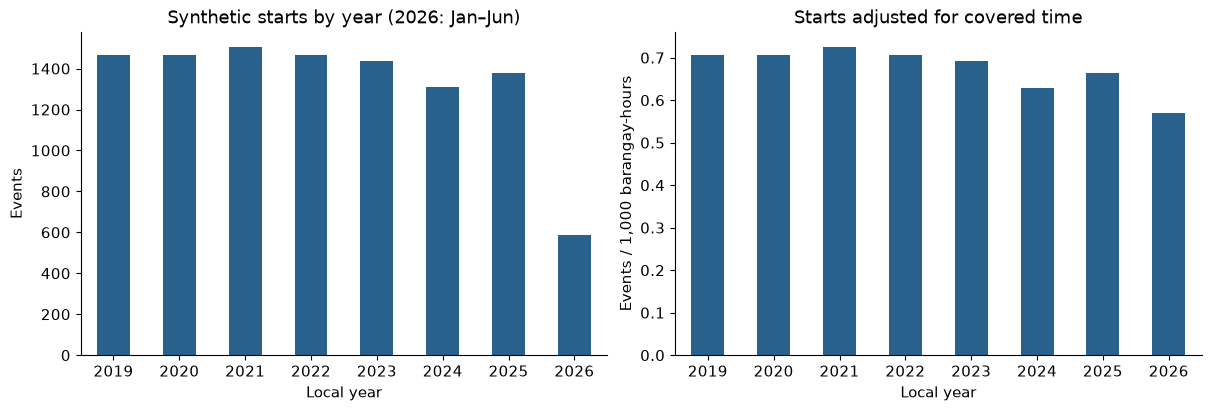

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
annual_summary.events.plot.bar(ax=axes[0], color=BLUE, rot=0)
annual_summary.events_per_1000_barangay_hours.plot.bar(ax=axes[1], color=BLUE, rot=0)
axes[0].set(title="Synthetic starts by year (2026: Jan–Jun)", xlabel="Local year", ylabel="Events")
axes[1].set(title="Starts adjusted for covered time", xlabel="Local year", ylabel="Events / 1,000 barangay-hours")
for axis in axes:
    axis.set_ylim(bottom=0)
plt.show()

In [15]:
display(Markdown(f"**Interpretation:** 2025 contains {annual_summary.loc[2025, 'events']:,} events; "
    f"2026 contains {annual_summary.loc[2026, 'events']:,} across only "
    f"{annual_summary.loc[2026, 'covered_hours_per_barangay']:,} hours per barangay. "
    "The smaller 2026 count alone cannot establish a declining trend. The rate view corrects elapsed-time "
    "exposure but still compares different month mixes, and the generator rejects boundary-crossing durations."))

**Interpretation:** 2025 contains 1,378 events; 2026 contains 586 across only 4,343 hours per barangay. The smaller 2026 count alone cannot establish a declining trend. The rate view corrects elapsed-time exposure but still compares different month mixes, and the generator rejects boundary-crossing durations.

### Monthly timeline

First remove the timezone **after converting to Manila** to obtain local calendar months. `to_period('M')` labels each month as an ordered period; it does not average values. A monthly line reveals variability, but does not by itself establish statistically validated seasonality.

In [16]:
event_months = events.start_time.dt.tz_localize(None).dt.to_period("M")
exposure_months = covered_hours.tz_localize(None).to_period("M")
monthly_exposure = pd.Series(exposure_months).value_counts().sort_index()
monthly_counts = event_months.value_counts().reindex(monthly_exposure.index, fill_value=0).sort_index()
monthly_summary = pd.DataFrame({"events": monthly_counts, "hours_per_barangay": monthly_exposure})
monthly_summary["events_per_1000_barangay_hours"] = monthly_counts / (monthly_exposure * barangay_count) * 1000
assert monthly_summary.events.sum() == len(events)
assert monthly_summary.hours_per_barangay.sum() == exposure_hours
display(monthly_summary.tail(6).round(4))

,events,hours_per_barangay,events_per_1000_barangay_hours
2026-01,109,744,0.6182
2026-02,82,672,0.5149
2026-03,104,744,0.5898
2026-04,91,720,0.5333
2026-05,111,744,0.6295
2026-06,89,719,0.5223


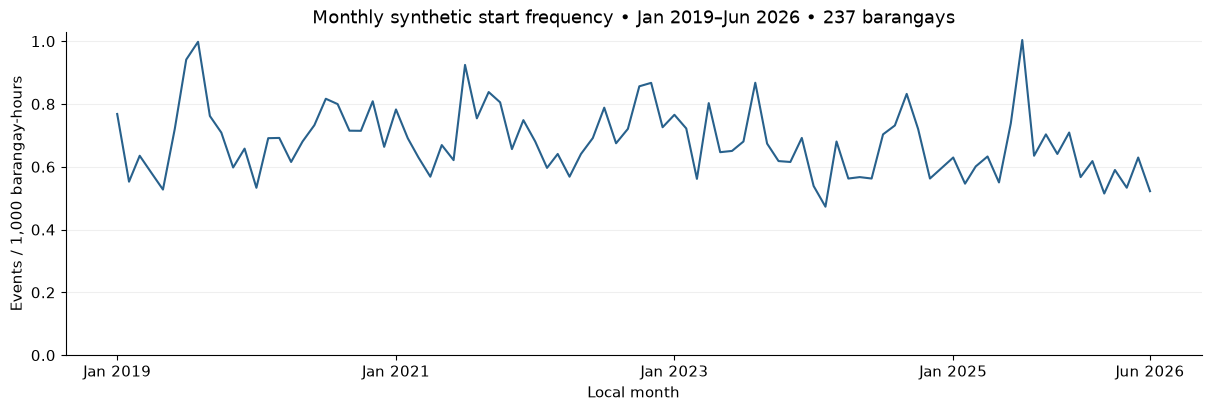

In [17]:
fig, axis = plt.subplots(figsize=(12, 4), layout="constrained")
month_dates = monthly_summary.index.to_timestamp()
axis.plot(month_dates, monthly_summary.events_per_1000_barangay_hours, color=BLUE, linewidth=1.5)
tick_positions = sorted(set([0, len(month_dates)-1, *range(24, len(month_dates), 24)]))
axis.set_xticks(month_dates[tick_positions], [month_dates[i].strftime("%b %Y") for i in tick_positions])
axis.set(title="Monthly synthetic start frequency • Jan 2019–Jun 2026 • 237 barangays",
         xlabel="Local month", ylabel="Events / 1,000 barangay-hours", ylim=(0, None))
axis.grid(axis="y", alpha=0.2)
plt.show()

In [18]:
peak_month = monthly_summary.events_per_1000_barangay_hours.idxmax()
display(Markdown(f"**Interpretation:** {peak_month} has the highest observed monthly frequency "
    f"({monthly_summary.loc[peak_month, 'events_per_1000_barangay_hours']:.3f} per 1,000 barangay-hours). "
    "A peak is descriptive; calling it an anomaly or attributing it to a storm requires additional evidence."))

**Interpretation:** 2025-07 has the highest observed monthly frequency (1.004 per 1,000 barangay-hours). A peak is descriptive; calling it an anomaly or attributing it to a storm requires additional evidence.

### Pooled calendar-month pattern

January–June occur eight times; July–December only seven. Month length also varies. Pool event counts and **sum actual exposure**, then divide. This is a weighted rate, not the unweighted mean of monthly rates. Pooling can hide changes between years; compare individual years as an exercise before calling this seasonality.

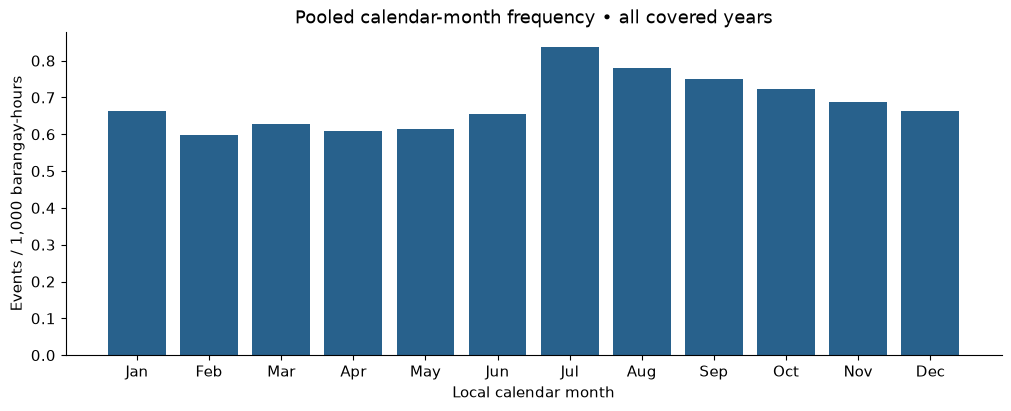

In [19]:
month_of_year_hours = pd.Series(covered_hours.month).value_counts().sort_index()
month_of_year_counts = events.start_time.dt.month.value_counts().reindex(range(1, 13), fill_value=0).sort_index()
seasonal_frequency = month_of_year_counts / (month_of_year_hours * barangay_count) * 1000
fig, axis = plt.subplots(layout="constrained")
axis.bar(range(1, 13), seasonal_frequency, color=BLUE)
axis.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
axis.set(title="Pooled calendar-month frequency • all covered years", xlabel="Local calendar month",
         ylabel="Events / 1,000 barangay-hours", ylim=(0, None))
plt.show()

**Interpretation:** the height of each bar describes the selected simulation over the observed exposure. The generator contains weather-conditioned heuristics, so any apparent environmental or seasonal association is partly imposed by design. This lesson does not test real-world seasonality, estimate causal effects or calculate significance from dependent hourly rows.

## 6. Initial geographic distributions

### Municipalities have different numbers of barangays

A municipality with more barangays has more simulated exposure. Aggregate on the municipality PSGC, then attach its authoritative name. Compare total counts and exposure-adjusted frequency together. Neither adjusts for population, customers, network length or reporting effort.

In [20]:
municipality_universe = boundaries.groupby(["municipality_psgc", "municipality"]).size().rename("barangays").reset_index()
municipality_events = events.groupby("municipality_psgc").size().rename("events")
municipality_summary = municipality_universe.join(municipality_events, on="municipality_psgc")
municipality_summary["events"] = municipality_summary.events.fillna(0).astype(int)
municipality_summary["events_per_1000_barangay_hours"] = municipality_summary.events / (municipality_summary.barangays * exposure_hours) * 1000
municipality_summary = municipality_summary.sort_values("events", ascending=True)
assert municipality_summary.events.sum() == len(events)
assert municipality_summary.barangays.sum() == barangay_count
display(municipality_summary.sort_values("events", ascending=False).round(4))

,municipality_psgc,municipality,barangays,events,events_per_1000_barangay_hours
3,0300804000,Dinalupihan,46,2054,0.6796
6,0300807000,Mariveles,18,1212,1.0248
2,0300803000,City of Balanga,25,997,0.6070
8,0300809000,Orani,29,943,0.4949
4,0300805000,Hermosa,23,936,0.6194
1,0300802000,Bagac,14,918,0.9980
9,0300810000,Orion,23,868,0.5744
10,0300811000,Pilar,19,788,0.6312
5,0300806000,Limay,12,591,0.7496
11,0300812000,Samal,14,503,0.5468


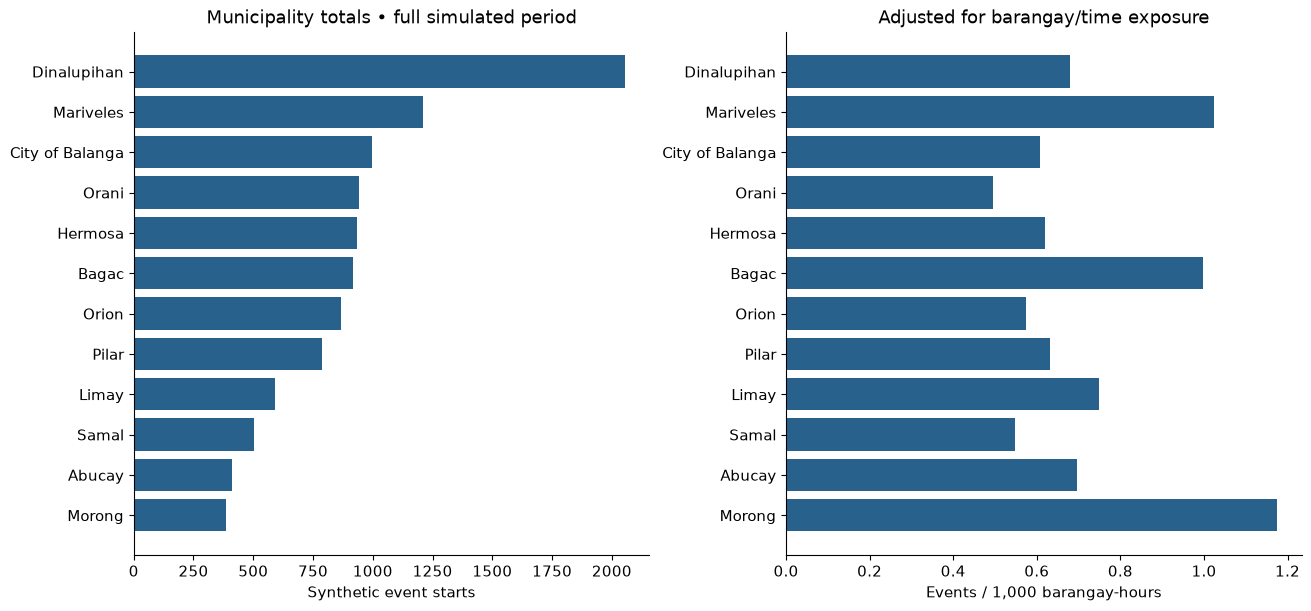

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout="constrained")
axes[0].barh(municipality_summary.municipality, municipality_summary.events, color=BLUE)
axes[1].barh(municipality_summary.municipality, municipality_summary.events_per_1000_barangay_hours, color=BLUE)
axes[0].set(title="Municipality totals • full simulated period", xlabel="Synthetic event starts")
axes[1].set(title="Adjusted for barangay/time exposure", xlabel="Events / 1,000 barangay-hours")
for axis in axes:
    axis.set_xlim(left=0)
plt.show()

In [22]:
largest_total = municipality_summary.loc[municipality_summary.events.idxmax()]
highest_rate = municipality_summary.loc[municipality_summary.events_per_1000_barangay_hours.idxmax()]
display(Markdown(f"**Interpretation:** {largest_total.municipality} has the most simulated starts "
    f"({largest_total.events:,}) across {largest_total.barangays} barangays. "
    f"{highest_rate.municipality} has the highest descriptive rate "
    f"({highest_rate.events_per_1000_barangay_hours:.3f} per 1,000 barangay-hours). "
    "Raw counts and rates answer different questions; neither is a real municipal reliability ranking."))

**Interpretation:** Dinalupihan has the most simulated starts (2,054) across 46 barangays. Morong has the highest descriptive rate (1.175 per 1,000 barangay-hours). Raw counts and rates answer different questions; neither is a real municipal reliability ranking.

### Barangay distribution and top examples

Join **from the complete boundary universe**, including zero-event barangays. A histogram shows spread across all barangays. A top-10 plot is a navigation aid, not a risk classification. Display municipality plus barangay name because names are not globally unique; PSGC remains the join key.

In [23]:
barangay_events = events.groupby("barangay_psgc").size().rename("events")
barangay_summary = boundaries.join(barangay_events, on="barangay_psgc")
barangay_summary["events"] = barangay_summary.events.fillna(0).astype(int)
assert len(barangay_summary) == barangay_count
assert barangay_summary.events.sum() == len(events)
display(barangay_summary.events.describe().to_frame("events per barangay across full exposure").round(2))
top_barangays = barangay_summary.nlargest(10, "events").sort_values("events")
top_labels = top_barangays.municipality + " / " + top_barangays.barangay

,events per barangay across full exposure
count,237.00
mean,44.76
std,18.46
min,14.00
25%,33.00
50%,41.00
75%,53.00
max,123.00


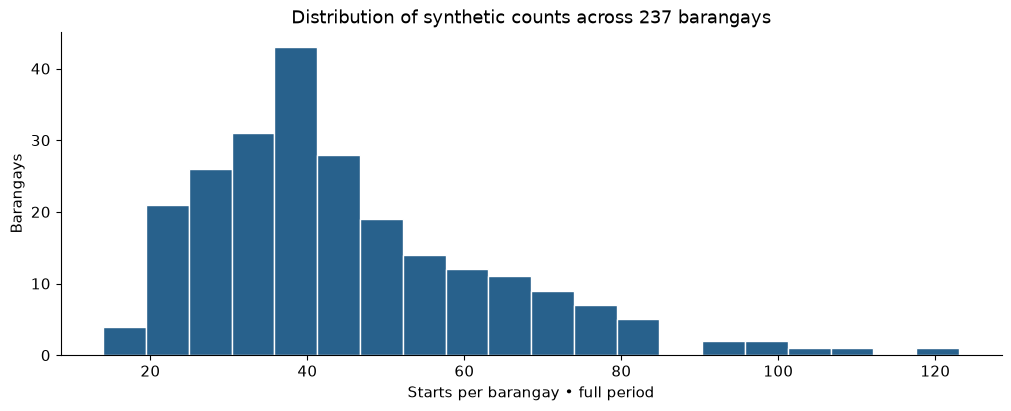

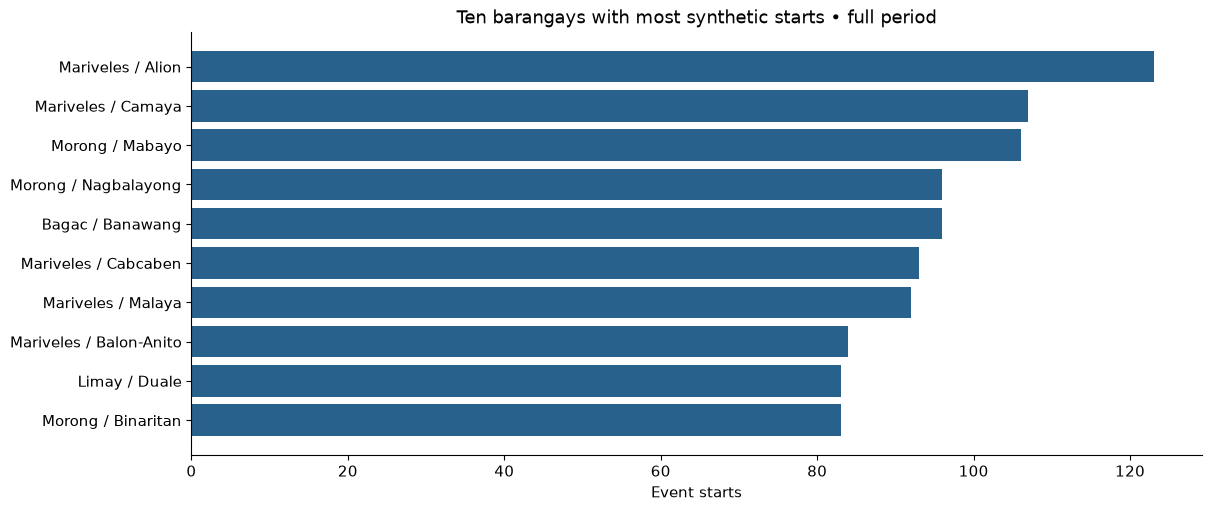

In [24]:
fig, axis = plt.subplots(layout="constrained")
axis.hist(barangay_summary.events, bins=20, color=BLUE, edgecolor="white")
axis.set(title="Distribution of synthetic counts across 237 barangays", xlabel="Starts per barangay • full period", ylabel="Barangays")
plt.show()

fig, axis = plt.subplots(figsize=(12, 5), layout="constrained")
axis.barh(top_labels, top_barangays.events, color=BLUE)
axis.set(title="Ten barangays with most synthetic starts • full period", xlabel="Event starts", xlim=(0, None))
plt.show()

**Interpretation:** each barangay shares the same declared time exposure in this simulation, so count ordering and time-normalized ordering agree within this universe. The counts are still shaped by generator assumptions, not measured network vulnerability. A boundary record establishes a location for dashboard navigation, not a calibrated risk category.

## 7. Generated causes and durations

### Cause composition

`value_counts` counts each generated category; percentage is `category count / all events × 100`. These are assigned simulation labels, not a real incident investigation. The generator's severity class is derived directly from duration: under 60 minutes is Minor, 60 to under 240 is Moderate, 240 or more is Major.

,events,share_pct
cause_category,,
Weather / Storm,3710,34.97
Vegetation / Tree Contact,3310,31.20
Equipment / Technical,2804,26.43
Other / Unknown,784,7.39


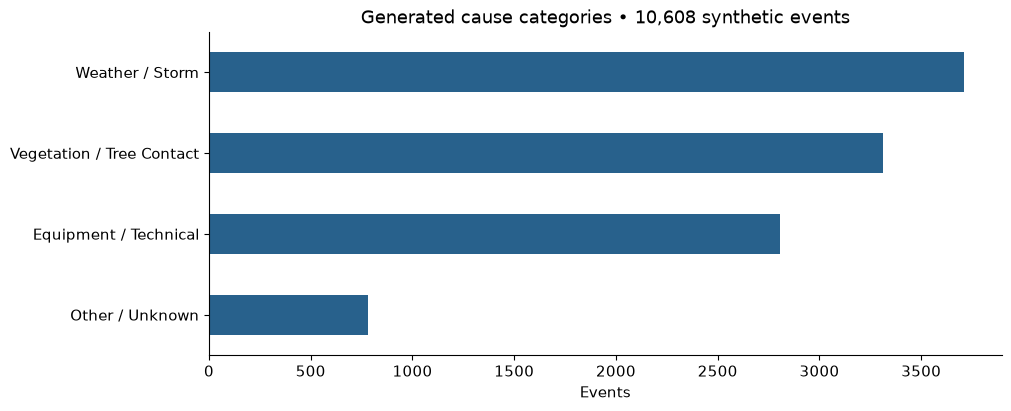

In [25]:
cause_summary = events.cause_category.value_counts().rename("events").to_frame()
cause_summary["share_pct"] = cause_summary.events / len(events) * 100
display(cause_summary.round(2))
assert cause_summary.events.sum() == len(events)
assert np.isclose(cause_summary.share_pct.sum(), 100)
expected_severity = np.where(events.duration_minutes < 60, "Minor",
                            np.where(events.duration_minutes < 240, "Moderate", "Major"))
assert events.severity_class.eq(expected_severity).all()
fig, axis = plt.subplots(layout="constrained")
cause_summary.sort_values("events").events.plot.barh(ax=axis, color=BLUE)
axis.set(title="Generated cause categories • 10,608 synthetic events", xlabel="Events", ylabel="")
plt.show()

**Interpretation:** Weather / Storm is the largest generated category (3,710, about 35.0%), followed by Vegetation / Tree Contact (3,310). These proportions describe the simulated recipe; they cannot establish PENELCO's actual cause mix. Severity is redundant with duration and is a post-event outcome.

### Distribution of duration

The **median** is the middle value. The **mean** is sensitive to long events. A 95th percentile means 95% of these simulated durations are at or below it; it is not a confidence interval. Plot the full duration range instead of silently clipping the long tail.

,duration (minutes)
count,10608.00
mean,192.05
std,156.48
min,15.00
50%,148.20
90%,373.61
95%,484.85
99%,783.72
max,1994.66


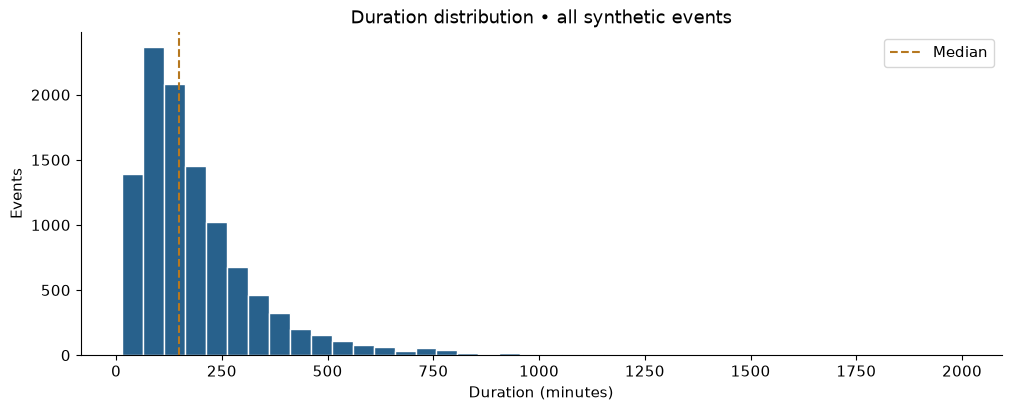

In [26]:
duration_summary = events.duration_minutes.describe(percentiles=[0.5, 0.9, 0.95, 0.99])
display(duration_summary.to_frame("duration (minutes)").round(2))
fig, axis = plt.subplots(layout="constrained")
axis.hist(events.duration_minutes, bins=40, color=BLUE, edgecolor="white")
axis.axvline(events.duration_minutes.median(), color=GOLD, linestyle="--", label="Median")
axis.set(title="Duration distribution • all synthetic events", xlabel="Duration (minutes)", ylabel="Events")
axis.legend()
plt.show()

In [27]:
display(Markdown(f"**Interpretation:** median duration is {events.duration_minutes.median():.2f} minutes; "
    f"mean is {events.duration_minutes.mean():.2f} minutes; "
    f"95th percentile is {events.duration_minutes.quantile(.95):.2f} minutes. "
    "The mean exceeding the median is consistent with a right tail. Durations are generated, "
    "and summed event duration is not province-wide downtime: different barangays can overlap."))

**Interpretation:** median duration is 148.20 minutes; mean is 192.05 minutes; 95th percentile is 484.85 minutes. The mean exceeding the median is consistent with a right tail. Durations are generated, and summed event duration is not province-wide downtime: different barangays can overlap.

## 8. Validation checks and limits of this lesson

Reconcile each summary back to the original event count, ensure no accidental mutation of the in-memory raw table, and verify the four input files retain their fingerprints. These are computational checks; they do not validate the simulator against observed outages.

**Why there is no weather correlation here:** this file contains only events, with no representative non-event comparison group. An association among event rows answers a conditional question such as duration among already generated events, not occurrence risk. Shared municipal weather, repeated barangay observations and autocorrelated time also violate naive independence assumptions. A later lesson must define the observation unit and comparison exposure, state the sample size and method, and separate imposed simulator relationships from scientific evidence.

In [28]:
reconciliation = pd.Series({"original events": len(events_raw), "annual counts": annual_summary.events.sum(),
    "monthly counts": monthly_summary.events.sum(), "municipality counts": municipality_summary.events.sum(),
    "barangay counts": barangay_summary.events.sum(), "cause counts": cause_summary.events.sum()})
assert reconciliation.eq(len(events_raw)).all()
assert events_raw.start_time.iloc[0] == "2019-01-01 08:00:00+08:00"
source_hashes_after = {name: file_sha256(path) for name, path in source_paths.items()}
assert source_hashes_before == source_hashes_after, "A source changed during the lesson."
display(reconciliation.to_frame("reconciled count"))
print("All lesson checks passed. Input fingerprints unchanged.")

,reconciled count
original events,10608
annual counts,10608
monthly counts,10608
municipality counts,10608
barangay counts,10608
cause counts,10608


All lesson checks passed. Input fingerprints unchanged.


## 9. Try it yourself

Work through these in order. The exercise cells are safe to run as supplied; replace comments with your own code. Check answers are included as assertions where useful.

1. **Filtering and counts:** select one municipality and count its events. Explain why a name filter is suitable for exploration but PSGC is preferable for production joins.
2. **Fair temporal comparison:** compare January–June 2025 against January–June 2026 with actual covered hours. Do not compare full-year 2025 to half-year 2026.
3. **Percentiles:** calculate the 90th percentile of duration. Explain why it is neither the mean nor a confidence interval.
4. **Aggregation:** change the top-10 barangay view to the bottom 10. Explain why the complete boundary universe must be retained.
5. **Methodology practice:** explain aloud why no missing values, an exact checksum and visible environmental associations do not establish operational forecasting skill.

In [29]:
selected_municipality = "Abucay"  # Change to another name shown in municipality_summary.
practice_events = events.loc[events.municipality.eq(selected_municipality)].copy()
print(f"{selected_municipality}: {len(practice_events):,} simulated events")
assert len(practice_events) == int(municipality_summary.loc[
    municipality_summary.municipality.eq(selected_municipality), "events"].iloc[0])
# Exercise: use practice_events.groupby(...) to count starts by year.

Abucay: 412 simulated events


In [30]:
# Exercise: filter events to months 1–6, then group starts by year for 2025 and 2026.
# Get matching exposure from monthly_summary (which retains the partial final hour).
# Divide each event count by (matching hours * barangay_count), then multiply by 1,000.
# Extension: plot each year's twelve monthly rates to inspect stability of the pooled pattern.

# Exercise: calculate events.duration_minutes.quantile(0.90).
# Check your answer with: assert np.isclose(your_result, 373.614)

# Exercise: use barangay_summary.nsmallest(10, "events") and plot those counts.

## 10. Summary, limitations and recommendations

The executable checks establish the following for this snapshot:

- **10,608 event rows and 51 fields**, all flagged synthetic; 237 barangays and 12 municipalities.
- Zero missing cells, blank text cells, duplicate IDs, repeated barangay starts, overlapping adjacent events, unparseable timestamps or geographic key/name mismatches.
- Stored durations match timestamp differences. Median **148.20 minutes**, mean **192.05 minutes**, 95th percentile **484.85 minutes**.
- Actual exposure is **1 January 2019 08:00 through 30 June 2026 23:00, UTC+8**. The last observed start is 21:00 on 30 June 2026; it does not define coverage.
- Counts vary across periods and places. Exposure-adjusted views prevent some misleading comparisons, but do not remove simulator design effects or prove real reliability differences.

**Not established:** real PENELCO outage accuracy, causal relationships, customer reliability indices, polygon topology quality, non-event environmental contrasts, archived forecast availability, or a valid 24–72-hour prediction target. Annual NDVI is retrospective; 2026 imagery extends through 23 September, after the labels end in June. Generator probabilities/scores and post-event outcomes are not prospective predictors.

**Review before continuing:** rerun all cells; inspect the quality guards; practice the five exercises; explain the event unit, denominator and synthetic caveat in your own words. The next proposed lesson covers weather timestamps and coverage, but it will be created only after your feedback. Future phase transitions also require your approval.

See `assessment/dataset_inventory.md` for the verified source inventory and `README.md` for the proposed notebook sequence. This notebook never depends on the legacy project's large panels.